# Chapter 8 — Developing the improved method

Everything in this chapter is **this project's extension**, not part of Adamik et al. (2024). Each of the five hypotheses of Chapter 7 becomes one small, switchable change, so that the original method remains runnable as a special case and every change can be tested alone. Code: `pel/improved_scoring.py`, `pel/improved_mapping.py`.

None of the ingredients is new as a technique: directed taxonomic typing, Lesk-style gloss overlap (Lesk 1986; Banerjee & Pedersen 2002) and popularity priors fused with other features (Shen et al. 2015) are textbook entity-linking and word-sense-disambiguation tools. What is examined here is whether they repair the specific weaknesses found in the PEL baseline.

In [1]:
# Locate the research/ directory and make the real implementation importable.
import sys, json
from pathlib import Path
RESEARCH = Path.cwd().resolve()
while not (RESEARCH / "pel").is_dir():
    RESEARCH = RESEARCH.parent
for path in (RESEARCH, RESEARCH / "experiments"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
FIGURES = RESEARCH / "experiments" / "figures"
RESULTS = RESEARCH / "experiments" / "results"
%matplotlib inline
import inspect
import numpy as np
from IPython.display import Image
from pel import improved_scoring, improved_mapping
from pel.improved_scoring import (FusionWeights, directed_hypernym_similarity, gloss_overlap,
                                  label_synsets, type_score, class_senses)
from pel.improved_mapping import ImprovedConfig, ORIGINAL_DISAMBIGUATION, improved_map_label, candidate_names
from pel.recorded_access import RecordedAccess
from pel.mapping import map_label
from pel.wordnet_access import get_synsets, path_similarity
wikidata, yago = RecordedAccess("coco", "wikidata"), RecordedAccess("coco", "yago")
report = json.loads((RESULTS / "improvements" / "analysis_L_links.json").read_text())
def development(method):
    return "   ".join(f"{kg} {report['development'][kg]['methods'][method]['hit@1']:.3f}" for kg in report["knowledge_graphs"])

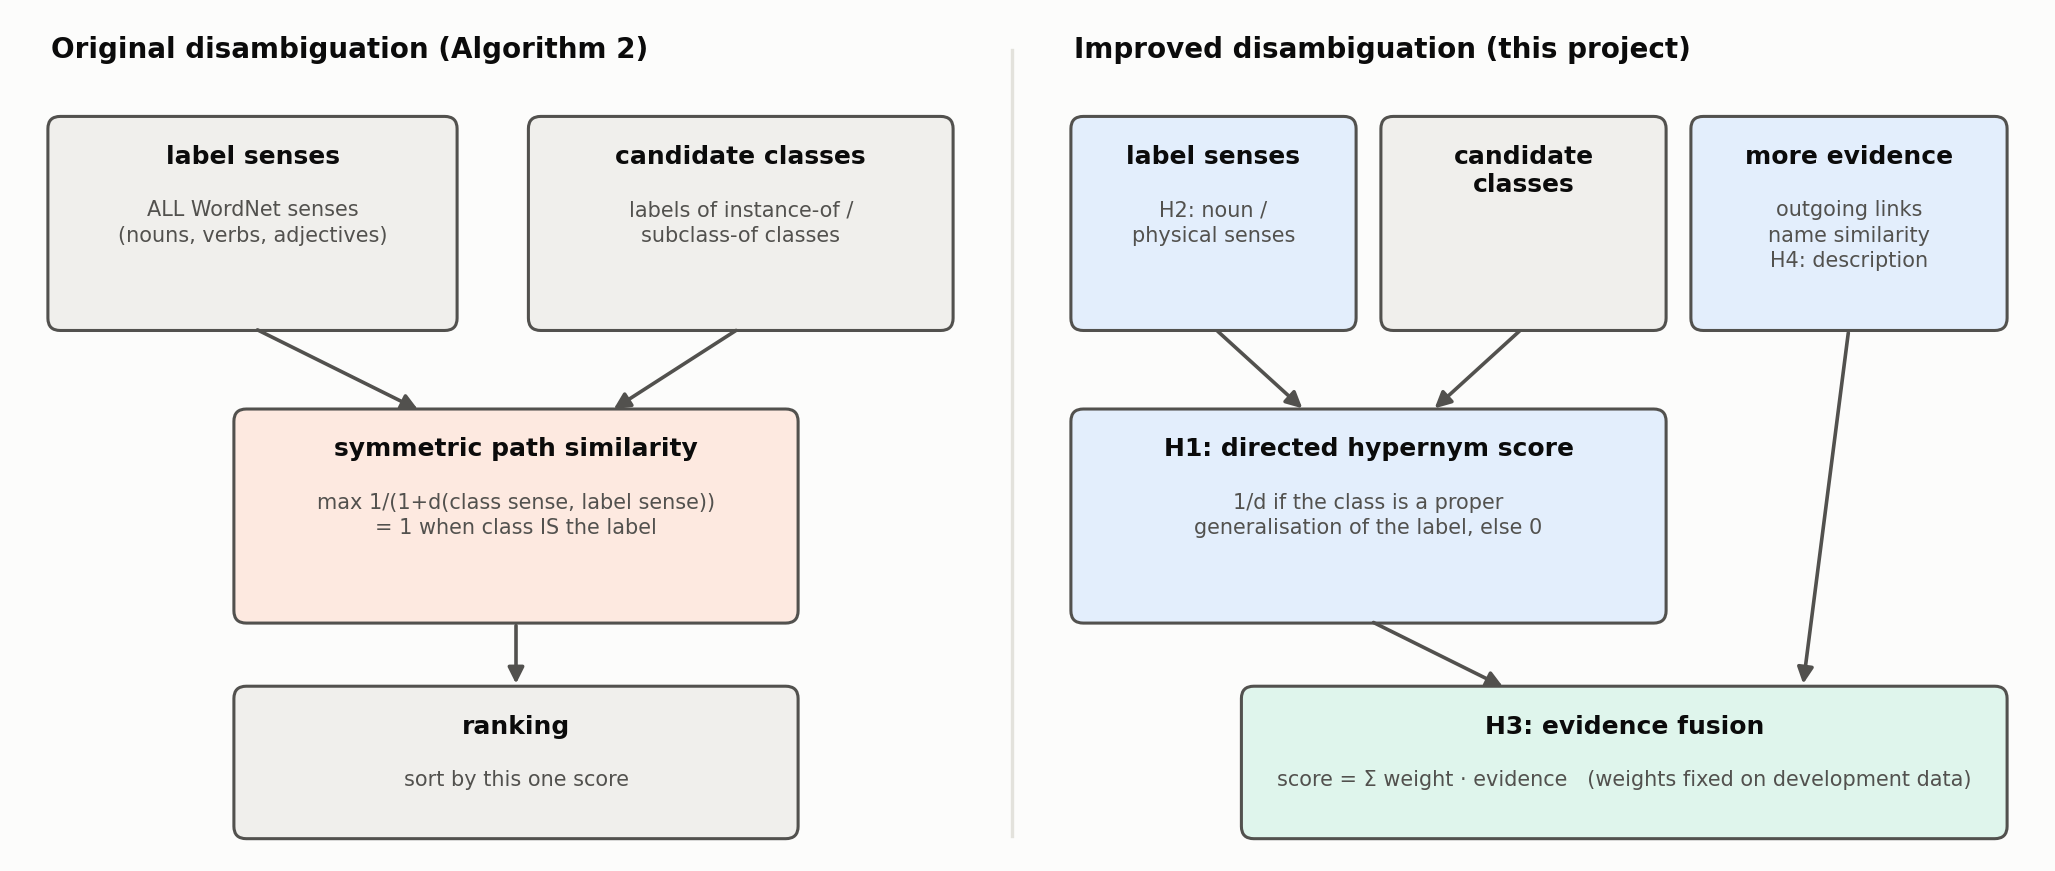

In [2]:
Image(filename=str(FIGURES / "concepts" / "original_vs_improved_disambiguation.png"), width=950)

## 8.1 H1 — a directed hypernym score

**Original mechanism.** $\mathrm{sim}_{path}(s,t) = 1/(1+d(s,t))$, symmetric, maximal when class and label are the same concept.

**Limitation.** The instance trap (Chapter 7.2).

**Idea.** The entity that denotes concept $t$ is typed by *generalisations* of $t$. So ask a directed question: is the candidate's class an ancestor of the label sense, and how close?

**Definition.** Let $d_\uparrow(t, k)$ be the number of hypernym edges from label sense $t$ up to class sense $k$ (undefined if $k$ is not an ancestor of $t$).

$$\mathrm{sim}_{hyp}(k, t) = \begin{cases} 1/d_\uparrow(t,k) & k \text{ is a proper ancestor of } t \;(d_\uparrow \ge 1)\\ 0 & \text{otherwise (same concept, descendant, sibling, unrelated)}\end{cases}$$

The maximum, 1, is now reached when the class is the *direct hypernym* — exactly the situation of a correctly modelled concept node.

| relation of class $k$ to label sense $t$ | original $\mathrm{sim}_{path}$ | directed $\mathrm{sim}_{hyp}$ |
|---|---|---|
| same concept | **1.0** | 0 |
| direct hypernym | 0.5 | **1.0** |
| grandparent | 0.33 | 0.5 |
| child (more specific) | 0.5 | 0 |
| sibling | 0.33 | 0 |

In [3]:
print(inspect.getsource(improved_scoring.directed_hypernym_similarity).split('"""')[2])
dog = get_synsets("dog")[0]
for word in ("dog", "domestic animal", "canine", "animal", "puppy", "cat"):
    k = [s for s in get_synsets(word) if s.pos() == "n"]
    print(f"class {word!r:18} original {max(path_similarity(s, dog) for s in k):.2f}   directed {max(directed_hypernym_similarity(s, dog) for s in k):.2f}")


    distance = _min_hypernym_distance(label_synset, class_synset)
    return 0.0 if not distance else 1.0 / distance

class 'dog'              original 1.00   directed 0.00
class 'domestic animal'  original 0.50   directed 1.00
class 'canine'           original 0.50   directed 1.00
class 'animal'           original 0.33   directed 0.50
class 'puppy'            original 0.50   directed 0.00
class 'cat'              original 0.20   directed 0.00


**The algorithm changes in one line** — the similarity called inside Algorithm 2's inner loop. On YAGO, where the trap is most severe:

In [4]:
H1 = ImprovedConfig(directed=True)
for label in ("apple", "bicycle", "truck"):
    before = map_label(label, yago, "L_links", "fc+fd")[0].split("/")[-1]
    after = improved_map_label(label, yago, "L_links", H1)[0].split("/")[-1]
    print(f"{label:8s} original f_c+f_d -> {before:28s} with H1 -> {after}")
print("\ndevelopment hit@1   original f_c+f_d:", development("fc+fd"))
print("development hit@1   H1              :", development("H1 directed hypernym score"))
print("development hit@1   original f_c    :", development("fc"))

apple    original f_c+f_d -> Apple_generic_instance       with H1 -> Apple


bicycle  original f_c+f_d -> Wheel_generic_instance       with H1 -> Bicycle
truck    original f_c+f_d -> Truck_generic_instance       with H1 -> Truck

development hit@1   original f_c+f_d: wikidata 0.434   dbpedia 0.639   yago 0.158
development hit@1   H1              : wikidata 0.566   dbpedia 0.653   yago 0.579
development hit@1   original f_c    : wikidata 0.616   dbpedia 0.653   yago 0.592


**Benefit and trade-off.** H1 removes most of the damage Algorithm 2 does on WikiData and YAGO. But compare with the last line: it only brings disambiguation back to about the level of *not disambiguating at all*. The directed score is zero for most candidates (fewer class labels qualify as ancestors), so the order is largely the pool order. H1 repairs; it does not add much. And on DBpedia it changes nothing, because DBpedia has no instance trap.

## 8.2 H2 — restricting the sense inventory

**Idea.** A detector label names a kind of thing. Drop verb/adjective senses (**noun**), or keep only noun senses below `physical_entity.n.01` (**physical**) — the paper's own “physical prior”, made explicit. A restricted inventory falls back to the wider one when it would be empty.

In [5]:
for label in ("couch", "orange", "bear"):
    for inventory in ("all", "noun", "physical"):
        print(f"{label:7s} {inventory:9s} senses {len(label_synsets(label, inventory)):2d}   names {[n for _, n in candidate_names(label, inventory)][:8]}")
    print()
print("development hit@1   original f_c+f_d:", development("fc+fd"))
print("development hit@1   H2 noun         :", development("H2 noun senses"))
print("development hit@1   H2 physical     :", development("H2 physical senses"))

couch   all       senses  4   names ['couch', 'lounge', 'sofa', 'cast', 'put', 'redact', 'frame']
couch   noun      senses  3   names ['couch', 'lounge', 'sofa']
couch   physical  senses  3   names ['couch', 'lounge', 'sofa']

orange  all       senses  6   names ['orange', 'Orange', 'orangish', 'orangeness', 'orange tree', 'Orange River']
orange  noun      senses  5   names ['orange', 'Orange', 'orangeness', 'orange tree', 'Orange River']
orange  physical  senses  4   names ['orange', 'Orange', 'orange tree', 'Orange River']

bear    all       senses 15   names ['bear', 'wear', 'behave', 'deport', 'deliver', 'gestate', 'tolerate', 'pay']
bear    noun      senses  2   names ['bear']
bear    physical  senses  2   names ['bear']

development hit@1   original f_c+f_d: wikidata 0.434   dbpedia 0.639   yago 0.158
development hit@1   H2 noun         : wikidata 0.445   dbpedia 0.680   yago 0.161
development hit@1   H2 physical     : wikidata 0.450   dbpedia 0.694   yago 0.155


The name lists become much cleaner. The accuracy hardly moves on WikiData and YAGO; on DBpedia's small development set (147 entries) it rises by four to five points. Why so little? A polluting name only matters if it retrieves an entity that then *wins*, and in most cases the verb-derived names retrieve nothing, or something that loses anyway. `couch` is a vivid example, not a typical one. Whether the DBpedia gain is real is for the test set to decide (Chapter 9).

## 8.3 H3 — evidence fusion

**Original mechanism.** One signal per ranking.

**Idea.** Add the signals. For candidate $c$ of label $l$:

$$\mathrm{score}(c) = w_n\,\underbrace{\mathrm{sim}_{lev}(\text{name}_c, l)}_{\text{found under which name?}} + w_t\,\underbrace{\mathrm{type}(c)}_{\text{class fits?}} + w_g\,\underbrace{\mathrm{gloss}(c)}_{\text{description fits? (H4)}} + w_p\,\underbrace{\frac{\log(1+\mathrm{links}(c))}{\log(1+\max_{c'}\mathrm{links}(c'))}}_{\text{popularity}}$$

with $w \ge 0$, $\sum w = 1$. The logarithm tames the heavy tail of link counts; dividing by the pool maximum makes popularity comparable across labels. Weights are chosen once, for all graphs, by grid search (step 0.1) on the development set.

The original processes are corner cases: $w_p = 1$ is $f_c$ on a `_links` query; $w_t = 1$ with the symmetric type score is $f_c + f_d$.

In [6]:
print(inspect.getsource(improved_scoring.FusionWeights))
selected = report["selected_on_development"]
print("weights selected on development data:", {k: round(v, 1) for k, v in selected["weights"].items()},
      "| sense inventory:", selected["inventory"], "| class-label back-off:", selected["word_backoff"])
print("fusion of the ORIGINAL evidence only (H3 alone):", {k: round(v, 1) for k, v in selected["h3_weights"].items()})

@dataclass(frozen=True)
class FusionWeights:
    """score(c) = name·sim_lev + type·type_score + gloss·gloss_overlap + popularity·pop"""
    name: float = 0.0
    type: float = 1.0
    gloss: float = 0.0
    popularity: float = 0.0

    def score(self, features: dict) -> float:
        return (self.name * features["name"] + self.type * features["type"]
                + self.gloss * features["gloss"] + self.popularity * features["popularity"])

weights selected on development data: {'name': 0.2, 'type': 0.1, 'gloss': 0.3, 'popularity': 0.4} | sense inventory: physical | class-label back-off: False
fusion of the ORIGINAL evidence only (H3 alone): {'name': 0.2, 'type': 0.1, 'gloss': 0.0, 'popularity': 0.7}


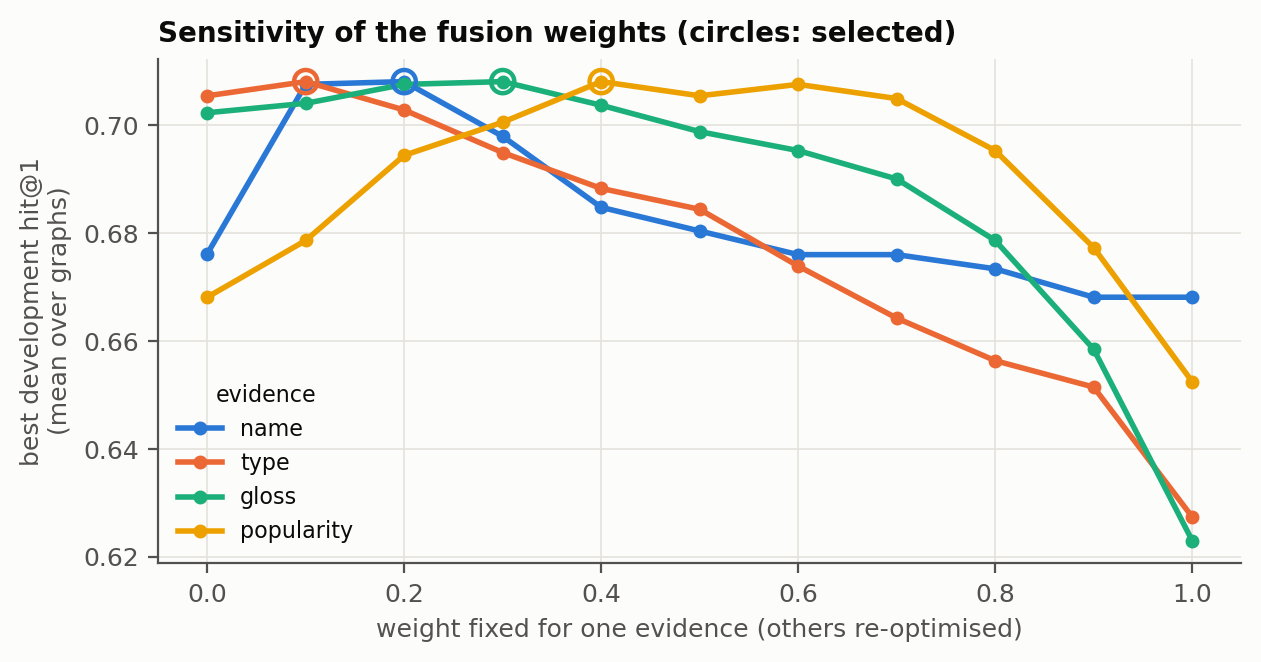

In [7]:
Image(filename=str(FIGURES / "improvements" / "weight_sensitivity_development.png"), width=620)

*Each line fixes one weight and re-optimises the others. The optimum is flat: what matters is that popularity gets a substantial but not exclusive share. Weight 0 for popularity is clearly worse; so is weight 1 (which is the original $f_c$).*

## 8.4 H4 — gloss–description overlap

**Limitation addressed.** Class labels are the only semantic evidence, and for roughly half of all candidates they yield nothing. Yet nearly every entity carries a one-line description.

**Idea (extended Lesk).** The right sense of the label and the right entity should be *described in similar words*. Let $\mathrm{sig}(t)$ be the content words of the WordNet gloss and lemmas of sense $t$ and of its direct hypernyms, and $W(c)$ the content words of the entity's description:

$$\mathrm{gloss}(c) = \max_{t \in \mathrm{Syn}(l)} \frac{|\mathrm{sig}(t) \cap W(c)|}{\sqrt{|\mathrm{sig}(t)|\cdot|W(c)|}}$$

In [8]:
senses = label_synsets("orange", "physical")
print("signature of orange.n.01:", sorted(improved_scoring.sense_signature(senses[0]))[:14], "...")
rows = wikidata.retrieve("orange", "L_links") + wikidata.retrieve("Orange", "L_links")[:3]
descriptions = wikidata.descriptions([iri for iri, _ in rows])
for iri, _ in rows:
    print(f"{gloss_overlap(senses, descriptions[iri]):.2f}  {descriptions[iri][:70]}")

signature of orange.n.01: ['citrou', 'citru', 'fruit', 'genu', 'grown', 'juicy', 'numerou', 'orange', 'pulp', 'region', 'rind', 'round', 'several', 'thick'] ...
0.49  citrus fruit of the orange tree
0.10  colour, located between red and yellow in the spectrum of light
0.20  eye color
0.00  heraldic tincture
0.00  word in the English language
0.00  French multinational telecommunications enterprise
0.00  commune in Vaucluse, France
0.12  city in Orange County, California, United States


## 8.5 H5 — class-label word back-off

Class labels such as “fruit of Maloideae” or “type of vehicle” are not WordNet entries and contribute nothing. With back-off, an unknown phrase contributes the senses of its content words.

In [9]:
for phrase in ("citrus fruit", "fruit of Maloideae", "type of vehicle", "city in the United States"):
    print(f"{phrase!r:30} without back-off: {len(class_senses(phrase, 'noun', False)):2d} senses   with: "
          f"{sorted({s.name().split('.')[0] for s in class_senses(phrase, 'noun', True)})[:5]}")
print("\ndevelopment hit@1   original f_c+f_d:", development("fc+fd"))
print("development hit@1   H5              :", development("H5 class-label word back-off"))

'citrus fruit'                 without back-off:  1 senses   with: ['citrus']
'fruit of Maloideae'           without back-off:  0 senses   with: ['fruit', 'yield']
'type of vehicle'              without back-off:  0 senses   with: ['character', 'fomite', 'type', 'vehicle']
'city in the United States'    without back-off:  0 senses   with: ['city', 'connect', 'country', 'department_of_state', 'joined']

development hit@1   original f_c+f_d: wikidata 0.434   dbpedia 0.639   yago 0.158
development hit@1   H5              : wikidata 0.442   dbpedia 0.626   yago 0.182


The last example shows the risk: the head of “city in the United States” is *city*, but back-off also offers *states*. The development gain is small, and the grid search did not select H5 for the combined method.

## 8.6 The combined method

`ImprovedConfig` holds the switches; `improved_map_label` has the same signature as the original `map_label`.

In [10]:
print(inspect.getsource(improved_mapping.score_candidates).split('"""')[2])


    senses = label_synsets(label, config.inventory)
    class_inventory = "all" if config.inventory == "all" else "noun"
    max_links = max((candidate.links or 0 for candidate in candidates), default=0)
    scored = []
    for candidate in candidates:
        evidence = {
            "name": candidate.name_similarity,
            "type": type_score(senses, class_labels.get(candidate.iri, []), config.directed,
                               class_inventory, config.word_backoff),
            "gloss": (gloss_overlap(senses, descriptions.get(candidate.iri, ""))
                      if config.weights.gloss else 0.0),
            "popularity": popularity(candidate.links, max_links),
        }
        scored.append((config.weights.score(evidence), candidate, evidence))
    scored.sort(key=lambda row: -row[0])
    return scored



In [11]:
weights = FusionWeights(**selected["weights"])
COMBINED = ImprovedConfig(inventory=selected["inventory"], directed=True, weights=weights,
                          word_backoff=selected["word_backoff"])

# sanity: with its switches off, the improved code IS the original method
assert all(improved_map_label(l, wikidata, "L_links", ORIGINAL_DISAMBIGUATION) == map_label(l, wikidata, "L_links", "fc+fd")
           for l in ("orange", "couch", "dog"))

for label in ("orange", "couch", "dog"):
    print(label)
    for score, candidate, evidence in improved_map_label(label, wikidata, "L_links", COMBINED, explain=True)[:3]:
        description = wikidata.descriptions([candidate.iri])[candidate.iri][:44]
        print(f"   {score:.2f}  {description:46s} " + "  ".join(f"{k} {v:.2f}" for k, v in evidence.items()))

orange
   0.85  citrus fruit of the orange tree                name 1.00  type 1.00  gloss 0.49  popularity 1.00
   0.63  major river of southern Africa                 name 0.42  type 1.00  gloss 0.26  popularity 0.92
   0.63  colour, located between red and yellow in th   name 1.00  type 0.00  gloss 0.10  popularity 1.00
couch
   0.73  piece of furniture for seating two or more p   name 1.00  type 0.50  gloss 0.25  popularity 1.00
   0.57  long seating furniture primarily used for re   name 1.00  type 0.50  gloss 0.25  popularity 0.62
   0.35                                                 name 1.00  type 0.00  gloss 0.00  popularity 0.36
dog
   0.65  domesticated mammal of the family Canidae      name 1.00  type 0.00  gloss 0.18  popularity 1.00
   0.46  sausage in bun, usually with toppings          name 0.43  type 0.00  gloss 0.12  popularity 0.84
   0.45  motif                                          name 1.00  type 0.00  gloss 0.00  popularity 0.61


The three running examples now come out right: the fruit, the sofa, the animal. Read the evidence columns — each decision is carried by a different mixture. For `orange` all four signals agree, and the colour (type 0 under the physical inventory) and the river (found under a distant name) fall behind. For `couch` the picture frame is gone: it was found under a verb synonym, which the physical inventory no longer offers. For `dog` the type evidence is 0 — WikiData's classes for the animal are phrases WordNet does not know — and name similarity plus popularity decide. (The stems in the signature look odd because plural folding is deliberately crude: it only has to be applied identically to both texts.)

## 8.7 Development-set summary

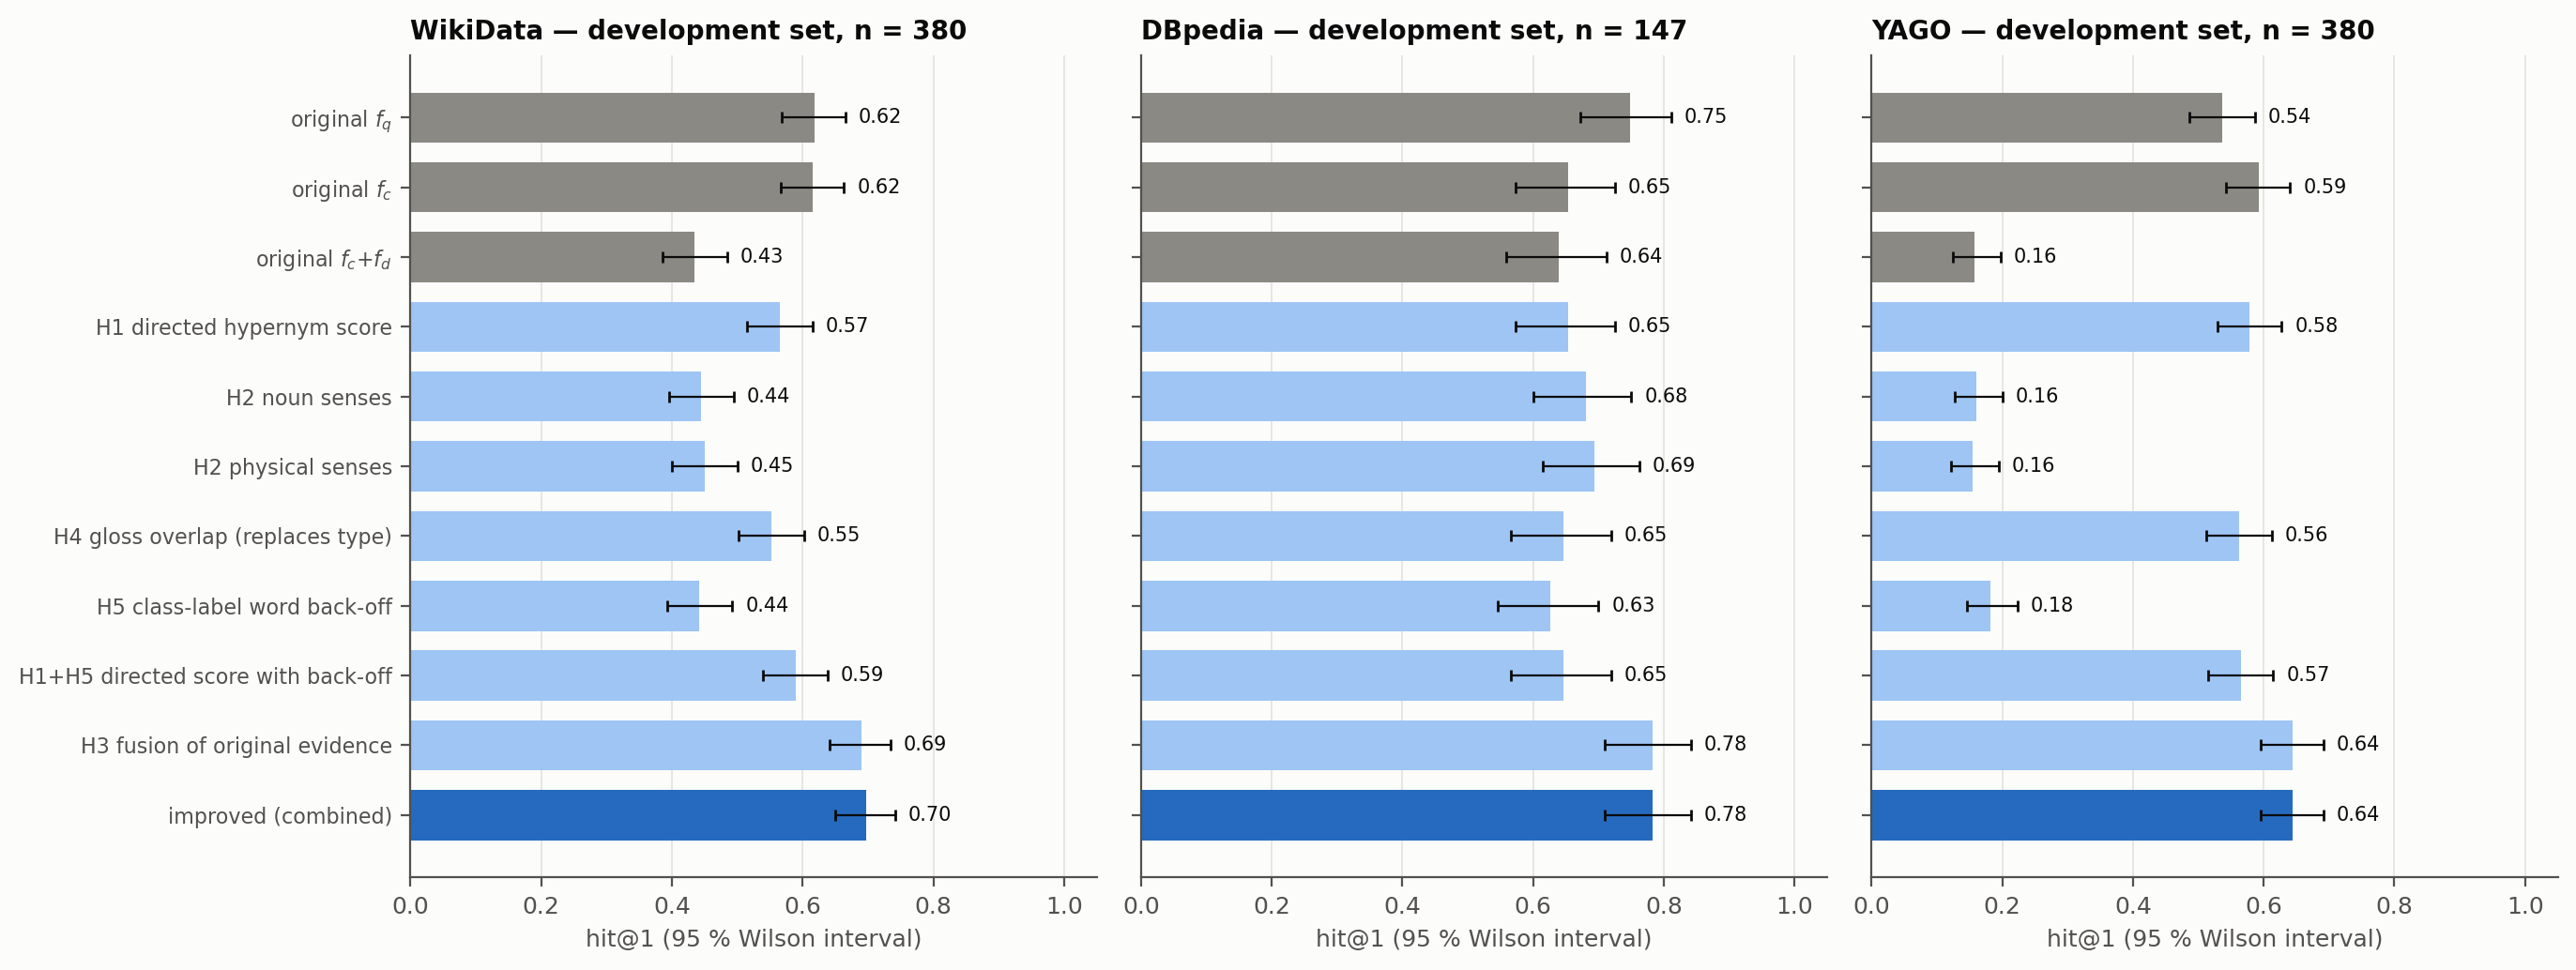

In [12]:
Image(filename=str(FIGURES / "improvements" / "methods_hit1_development.png"), width=1000)

*Development set (MS COCO + half of the Visual Genome sample). Grey: the three original processes. Light blue: one change applied to the original $f_c + f_d$. Dark blue: the combined method.*

On the data used to design them, H1, H3 and H4 help, H2 and H5 hardly do. But this is the data the choices were made on. Whether any of it holds on labels the method has never seen is the subject of Chapter 9.